<a href="https://colab.research.google.com/github/muhammad-usman-tech/data-analysis-tasks/blob/main/Task_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

shape of the df is :  (48895, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12

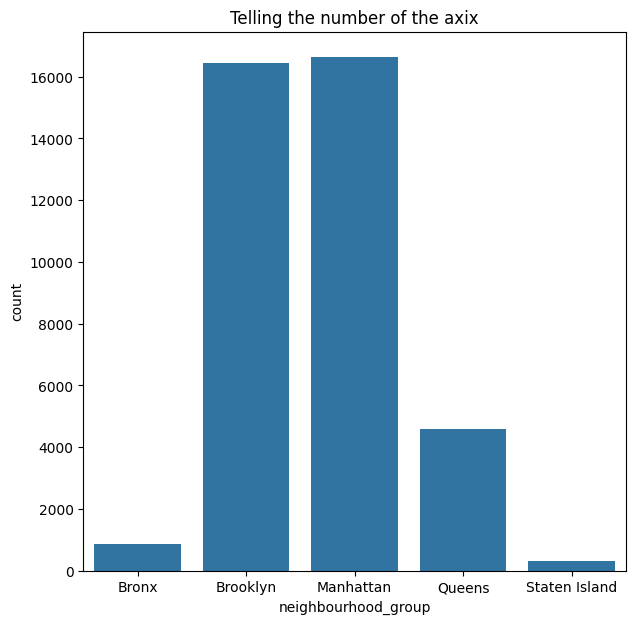

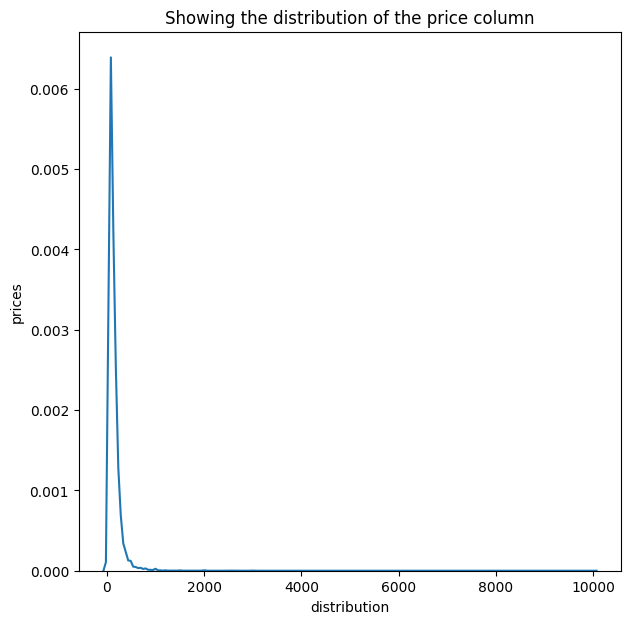

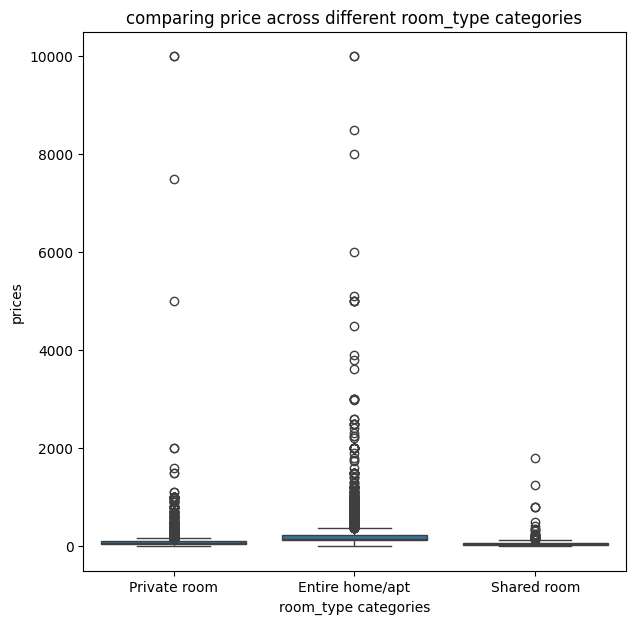

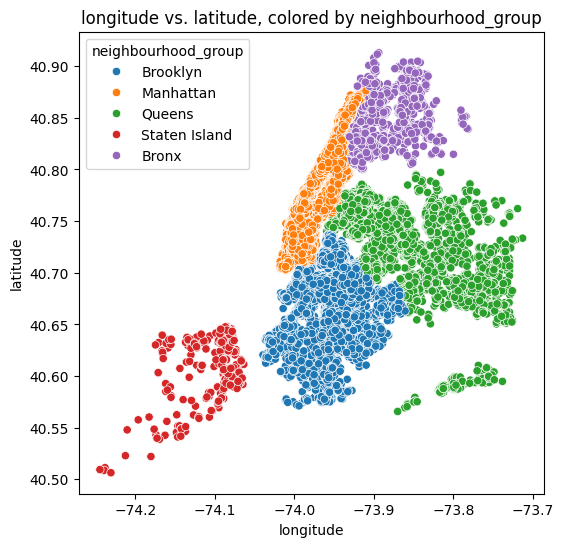

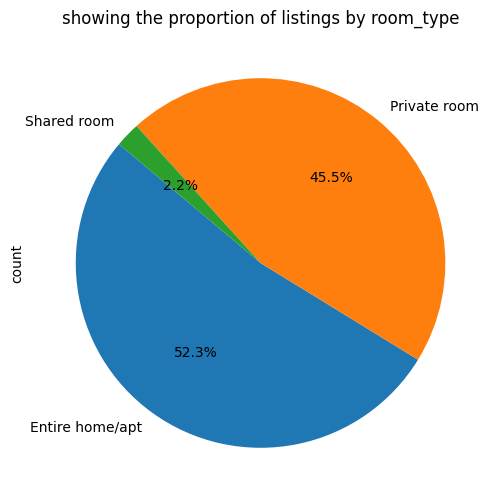

In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#104: loaded

df=pd.read_csv('/content/AB_NYC_2019.csv')
# 105:Perform EDA: shape, dtypes, missing values, descriptive statistics.
# according to me EDA stands for exploratery data analysis and in this we make the data ready for the aggregation phase

# shape
print('shape of the df is : ', df.shape)
#  we got 48 thousand and 8 hundred rows and the 16 attributes

# inspecting the datatypes
df.info()
df.head()
# ok so all the datatypes look quite good but the last_review 38843 non-null  object is something date and must be some date time
# try do it
df['last_review']=pd.to_datetime(df['last_review'],format='mixed')
# df.info() changed here

# now missing values i have to do and think it by my self and i have to think how can remove all the missing values and what can be the right approach
# firstly finding the percentage of the nulls then i will se what to do

null=df.isnull().sum()
per=(null/len(df))*100
per
# ok so last_review reviews_per_month have 22.55 percent
# we can also drop them but thats not a good way

drop_col=per[per>=50].index
drop_col
df=df.drop(columns=drop_col) # not column has more then 50 percent

# ok now filling each by their data types
#start with numeric(int and float)
num_col=df.select_dtypes(include=['number']).columns

num_col
df[num_col]=df[num_col].fillna(df[num_col].median())
# here now move to the object and the string

obj_col=df.select_dtypes(include=['object']).columns
obj_col
df[obj_col]=df[obj_col].fillna(df[obj_col].mode().iloc[0])
# done now go for the date and time

# date_time_col=df.select_dtypes(include=['datetime']).columns
# date_time_col
# df[date_time_col]=df[date_time_col].fillna(df[date_time_col].mode().iloc[0])
df.dropna(subset=['last_review'],inplace=True)
# done now check the percentage again

print('null values final check : ',(df.isnull().sum()/len(df))*100) #yes now all is 0(zero)

# now last descriptive statistics
statistics=df.describe(include='all')
statistics

#step 105 done by my side

# 106
data_bar=df.groupby('neighbourhood_group')['neighbourhood_group'].value_counts()

data_bar
plt.figure(figsize=(7,7))
sns.barplot(x=data_bar.index,y=data_bar.values)
plt.title('Telling the number of the axix')
plt.xlabel('neighbourhood_group')
plt.ylabel('count')
plt.show()
# interpretation: it is observed that the that 90 percent of the groups are brooklyn and manhattan which are indivisually almost 16000 and others groups are combined almost 5500



# 107:Create a histogram showing the distribution of price. Apply a log scale to the x-axis and
# explain why this is appropriate.
plt.figure(figsize=(7,7))
# with the log_scale=True it is some thing else to understand first of all just let me understand this simple histplot
sns.kdeplot(data=df['price'])
# can also use the histplot instead of the kde
plt.title('Showing the distribution of the price column')
plt.xlabel('distribution')
plt.ylabel('prices')
plt.show()

# interpretation: ok so it is observed from the kernal density plot that almost all prices of the rooms are less and only few prices are very high like more then the 2000,basically in the histplot there were very close lins on the 0 and upto almost 1000 so some times kde is easy to tell what you have understood

# 108:Create a box plot comparing price across different room_type categories.


plt.figure(figsize=(7,7))
sns.boxplot(x=df['room_type'],y=df['price'],data=df)
plt.title('comparing price across different room_type categories')
plt.xlabel('room_type categories')
plt.ylabel('prices')
plt.show()
# interetation: there were 3 room types and the prices of all the types of rooms are so close and show alot of noisy daya outer then the maximum wick all the median and the Q1 and the Q3 are almost very close in the all types of rooms


#109: Create a scatter plot of longitude vs. latitude, colored by neighbourhood_group, to
# visualize geographic clustering of listings.

plt.figure(figsize=(6,6))
sns.scatterplot(x=df['longitude'],y=df['latitude'],data=df,hue=df['neighbourhood_group'])
plt.title('longitude vs. latitude, colored by neighbourhood_group')
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.show()

# interpretation: it is truely observed that the there is no such strong relation is found between these 2 columns it was just a little weak relation(i also checked it by the regplot that showed a line)


# 110: Create a pie chart showing the proportion of listings by room_type.

data=df['room_type'].value_counts()
data

plt.figure(figsize=(6,6))
data.plot.pie(autopct='%1.1f%%', startangle=140)
plt.title('showing the proportion of listings by room_type')
plt.show()
# interpretation:  thsi pie chart shows that only 2.2 percent peaople list the shared rooms other visiters 52 percent chose the complete home/apt and almost 45 percent people chose the private rooms